In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate, ShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

### Visulization and EDA

In [33]:
df = pd.read_csv("D:\\Data science\\Assignments\\Questions\\KNN\\KNN\\Zoo.csv")
display(df)
display(df.describe())
display(df.isnull().sum())


,animal name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,type
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,wallaby,1,0,0,1,0,0,0,1,1,1,0,0,2,1,0,1,1
97,wasp,1,0,1,0,1,0,0,0,0,1,1,0,6,0,0,0,6
98,wolf,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1
99,worm,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,7


,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,type
count,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000
mean,0.425743,0.198020,0.584158,0.405941,0.237624,0.356436,0.554455,0.603960,0.821782,0.792079,0.079208,0.168317,2.841584,0.742574,0.128713,0.435644,2.831683
std,0.496921,0.400495,0.495325,0.493522,0.427750,0.481335,0.499505,0.491512,0.384605,0.407844,0.271410,0.376013,2.033385,0.439397,0.336552,0.498314,2.102709
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,1.000000
50%,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,4.000000,1.000000,0.000000,0.000000,2.000000
75%,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,4.000000,1.000000,0.000000,1.000000,4.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,8.000000,1.000000,1.000000,1.000000,7.000000


animal name    0
hair           0
feathers       0
eggs           0
milk           0
airborne       0
aquatic        0
predator       0
toothed        0
backbone       0
breathes       0
venomous       0
fins           0
legs           0
tail           0
domestic       0
catsize        0
type           0
dtype: int64

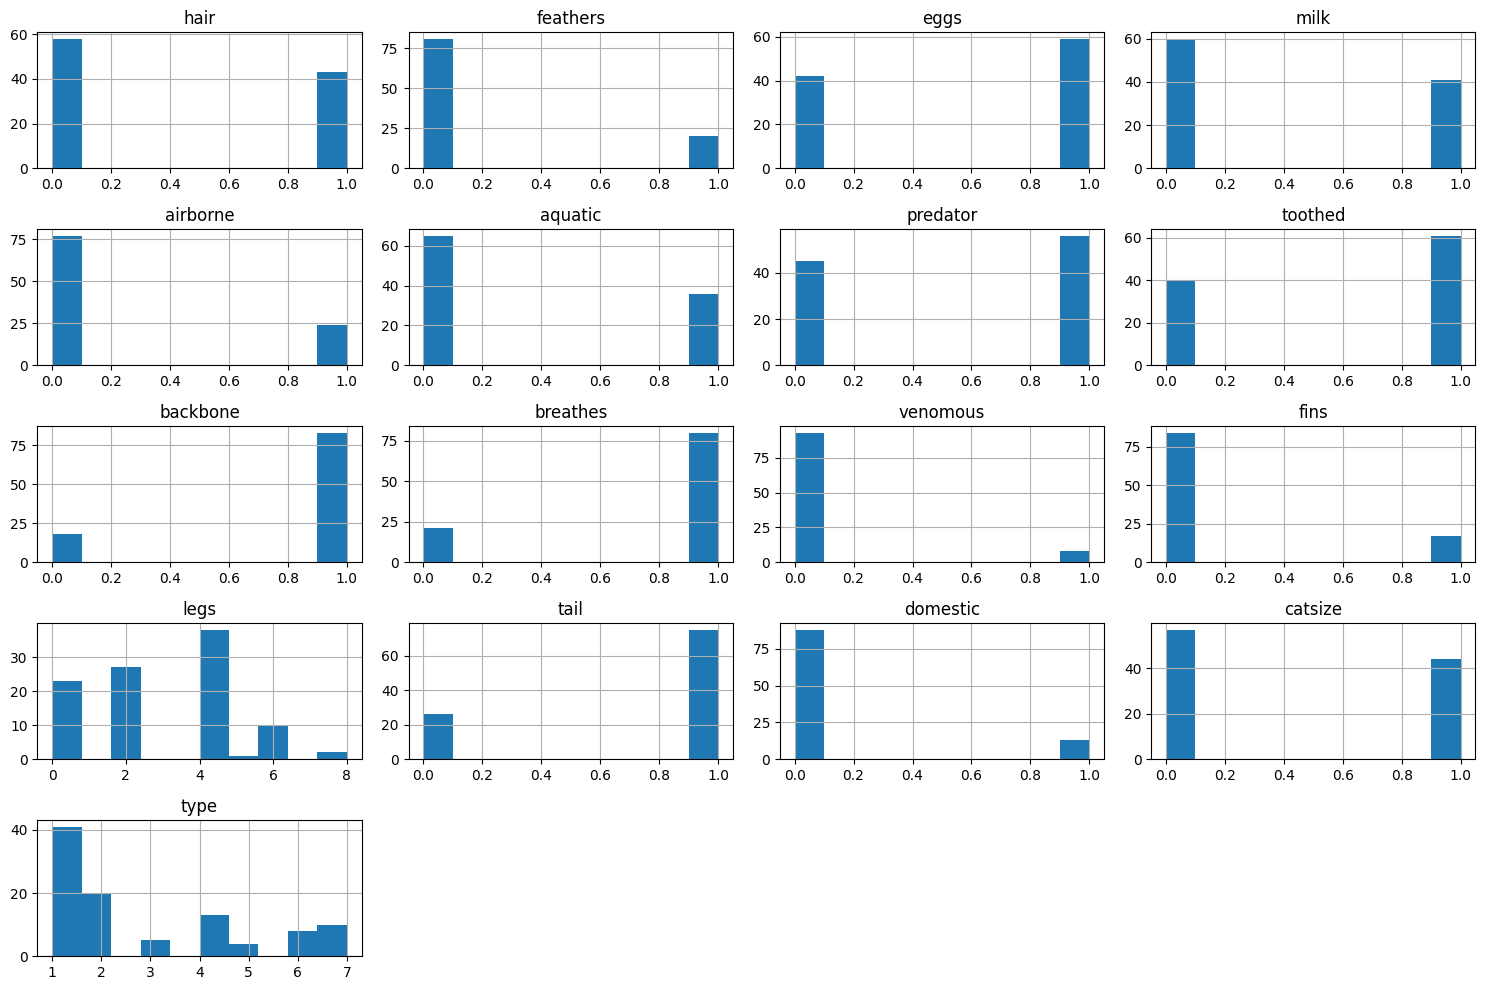

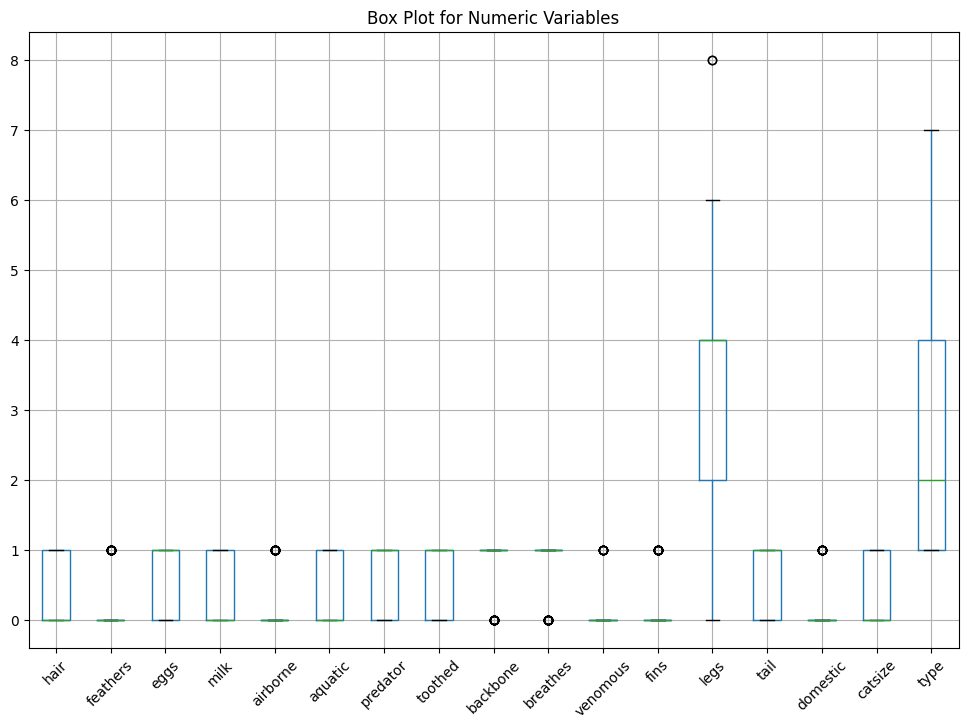

,animal name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,type
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1


In [34]:
def clean_data(df):
    # Fill missing values with column mean
    df = df.fillna(df.mean(numeric_only=True))
    # Plot histograms for all numeric columns in the DataFrame
    numeric_columns = ['hair', 'feathers', 'eggs', 'milk', 'airborne', 'aquatic', 'predator', 
                       'toothed', 'backbone', 'breathes', 'venomous', 'fins', 'legs', 
                       'tail', 'domestic', 'catsize', 'type']
    df.hist(figsize=(15,10))
    plt.tight_layout()
    plt.ylabel('Frequency')
    plt.show()
    # Plot box plot for all numeric variables
    df.boxplot(column=['hair', 'feathers', 'eggs', 'milk', 'airborne', 'aquatic', 
                       'predator', 'toothed', 'backbone', 'breathes', 'venomous', 
                       'fins', 'legs', 'tail', 'domestic', 'catsize', 'type'], 
               figsize=(12, 8), rot=45)
    plt.title("Box Plot for Numeric Variables")
    plt.show()
    # Remove outliers using Z-score method
    z_scores = (df.select_dtypes(include=[np.number]) - df.select_dtypes(include=[np.number]).mean()) / df.select_dtypes(include=[np.number]).std()
    df = df[(np.abs(z_scores) < 3).all(axis=1)]
    return df

df_clean = clean_data(df)
df_clean.head()

### Partationing and Model Fitting

In [35]:
X = df_clean.drop(['animal name', 'type'], axis=1)
Y = df_clean['type']

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (74, 16)
Testing set shape: (19, 16)


In [38]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
print("KNN classifier trained successfully.")

KNN classifier trained successfully.


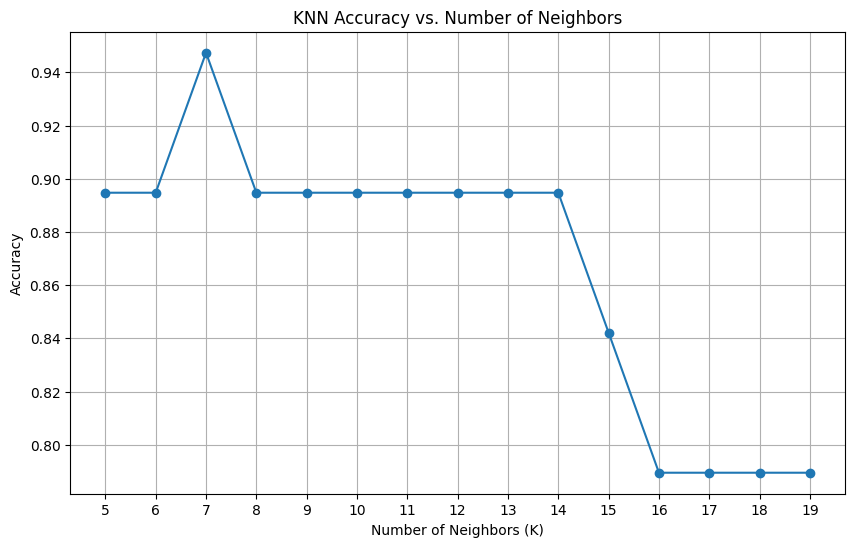


The optimal K value is: 7
The maximum accuracy achieved is: 0.9474


In [39]:
k_values = range(5, 20)  # Check K from 5 to 19
accuracy_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    accuracy_scores.append(accuracy)

# Plot the accuracy for different K values
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracy_scores, marker='o')
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs. Number of Neighbors")
plt.xticks(k_values)
plt.grid(True)
plt.show()

# Find the optimal K with the highest accuracy
optimal_k = k_values[accuracy_scores.index(max(accuracy_scores))]
print(f"\nThe optimal K value is: {optimal_k}")
print(f"The maximum accuracy achieved is: {max(accuracy_scores):.4f}")

In [45]:
knn_optimal = KNeighborsClassifier(n_neighbors=optimal_k)

# Train the classifier on the training data
knn_optimal.fit(X_train, y_train)
y_pred_optimal = knn_optimal.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_optimal)
precision = precision_score(y_test, y_pred_optimal, average='weighted') # Use weighted average for multi-class
recall = recall_score(y_test, y_pred_optimal, average='weighted') # Use weighted average for multi-class
f1 = f1_score(y_test, y_pred_optimal, average='weighted') # Use weighted average for multi-class

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

Accuracy: 0.9474
Precision: 0.8995
Recall: 0.9474
F1-score: 0.9223


c:\Users\abhir\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### Visualize of decision boundries

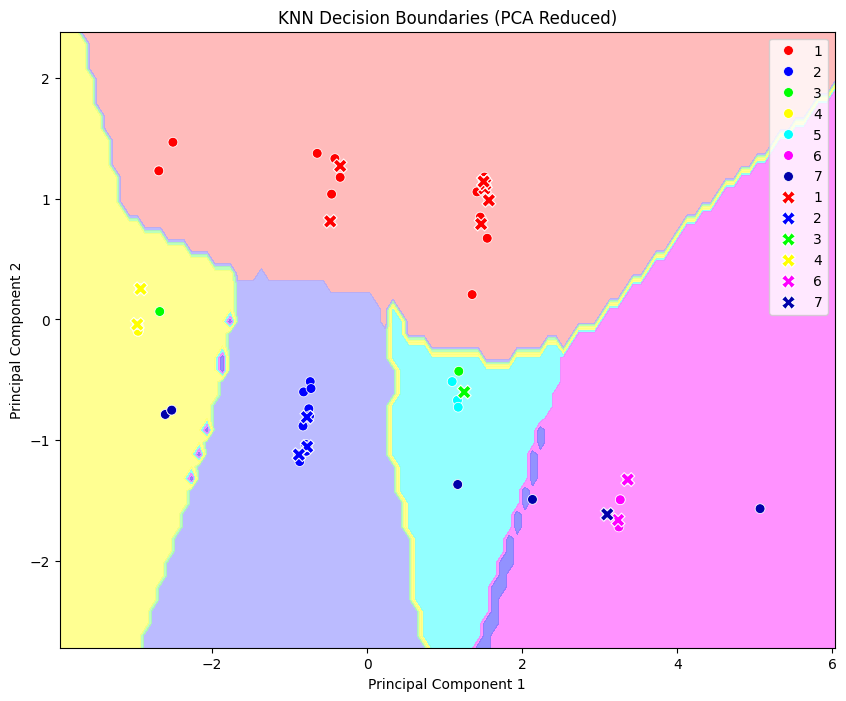

In [46]:
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap
import numpy as np

# Reduce dimensionality to 2 using PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Train a new KNN classifier on the PCA-transformed training data
knn_pca = KNeighborsClassifier(n_neighbors=optimal_k)
knn_pca.fit(X_train_pca, y_train)

# Create a meshgrid to plot the decision boundaries
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

# Predict the class for each point in the meshgrid
Z = knn_pca.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Create a colormap
cmap_light = ListedColormap(['#FFAAAA', '#AAAAFF', '#AAFFAA', '#FFFF77', '#77FFFF', '#FF77FF', '#7777FF'])
cmap_bold = ListedColormap(['#FF0000', '#0000FF', '#00FF00', '#FFFF00', '#00FFFF', '#FF00FF', '#0000AA'])

# Plot the decision boundaries and the data points
plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)

# Plot the training points
sns.scatterplot(x=X_train_pca[:, 0], y=X_train_pca[:, 1], hue=y_train, palette=cmap_bold, s=50) # Removed label

# Plot the testing points
sns.scatterplot(x=X_test_pca[:, 0], y=X_test_pca[:, 1], hue=y_test, palette=cmap_bold, marker='X', s=100) # Removed label


plt.title("KNN Decision Boundaries (PCA Reduced)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()

Visualizing decision boundaries for a dataset with 16 features is challenging. Decision boundaries are typically visualized in 2D or 3D space. To visualize the decision boundaries of this classifier, we would need to reduce the dimensionality of the data  
I have used AI to reduce the dimantionality using PCA and to visulize

### interview questions

##### 1. What are the key hyperparameters in KNN?
- n_neighbors (K): This is the most important hyperparameter. It determines the number of nearest neighbors to consider when making a prediction. Choosing an appropriate value for K is crucial  
- metric: This specifies the distance metric to use when calculating the distance between data points.


##### 2. What distance metrics can be used in KNN?
Euclidean Distance: This is the most common metric and is the straight-line distance between two points in Euclidean space. It is suitable for continuous numerical data.